# 07 湿気容量と吸放湿

30 m³の室、給排気各30 m³/h、外気絶対湿度の変化を、湿気容量の有無で比較する。

## 到達目標
x[kg/kg(DA)]、発湿[kg/s]。付加湿気容量は単位を明記。ここではkg/(kg/kg)を指定する。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/07/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "07"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'07_moisture': {'builder': {},
                 'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                          'end': '2026-01-01T23:00:00',
                                          'length': 24,
                                          'timestep': 3600}},
                 'nodes': [{'key': 'outside',
                            't': 20,
                            'x': [0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.01,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004,
                                  0.004]},
                           {'key': 'room', 't': 20, 'x': 0.006, 'calc_x': True, 'v': 30}],
                 'ventilation_branches': [{'key': 'outside->room',
                                           'source': 'outside',
                                           'target': 'room',
                                           'vol': 0.008333333333333333,
                                           'humidity_generation': 1e-06},
                                          {'key': 'room->outside',
                                           'source': 'room',
                                           'target': 'outside',
                                           'vol': 0.008333333333333333}],
                 'thermal_branches': []},
 '07_moisture_buffer': {'builder': {},
                        'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                                 'end': '2026-01-01T23:00:00',
                                                 'length': 24,
                                                 'timestep': 3600}},
                        'nodes': [{'key': 'outside',
                                   't': 20,
                                   'x': [0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.01,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004,
                                         0.004]},
                                  {'key': 'room', 't': 20, 'x': 0.006, 'calc_x': True, 'v': 30},
                                  {'key': 'buffer',
                                   't': 20,
                                   'x': 0.006,
                                   'calc_x': True,
                                   'moisture_capacity': 2,
                                   'moisture_capacity_unit': 'kg/(kg/kg)'}],
                        'ventilation_branches': [{'key': 'outside->room',
                                                  'source': 'outside',
                                                  'target': 'room',
                                                  'vol': 0.008333333333333333,
                                                  'humidity_generation': 1e-06},
                                                 {'key': 'room->outside',
                                                  'source': 'room',
                                                  'target': 'outside',
                                                  'vol': 0.008333333333333333}],
                        'thermal_branches': [{'key': 'room->buffer',
                                              'source': 'room',
                                              'target': 'buffer',
                                              'conductance': 0,
                                              'moisture_conductance': 0.002}]}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


07_moisture artifacts.1794699401759.output.a4f9fdb9bcb245d58886f08500bfea8a


07_moisture_buffer artifacts.1794699402791.output.46b014886eca4f32978e209f57c8bd05


07_moisture


,outside,room
time,,
2026-01-01 00:00:00,0.01,0.008050
2026-01-01 01:00:00,0.01,0.009075
2026-01-01 02:00:00,0.01,0.009588
2026-01-01 03:00:00,0.01,0.009844
2026-01-01 04:00:00,0.01,0.009972


07_moisture_buffer


,buffer,buffer_mx,outside,room
time,,,,
2026-01-01 00:00:00,0.007778,0.006889,0.01,0.008025
2026-01-01 01:00:00,0.008775,0.007832,0.01,0.009036
2026-01-01 02:00:00,0.009338,0.008585,0.01,0.009547
2026-01-01 03:00:00,0.009659,0.009122,0.01,0.009809
2026-01-01 04:00:00,0.009844,0.009483,0.01,0.009944


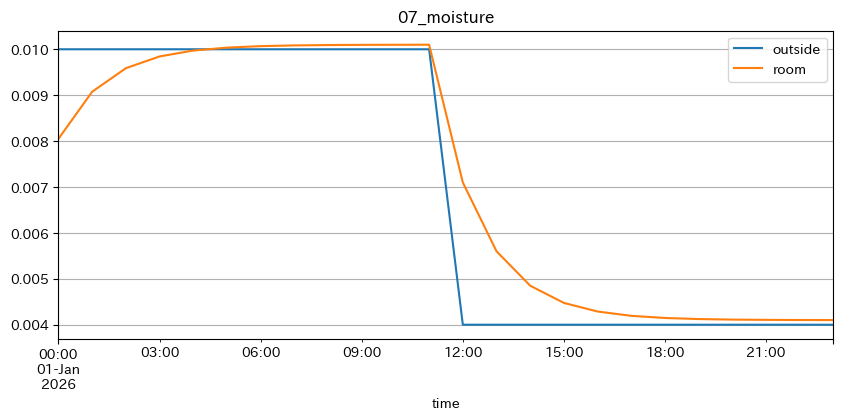

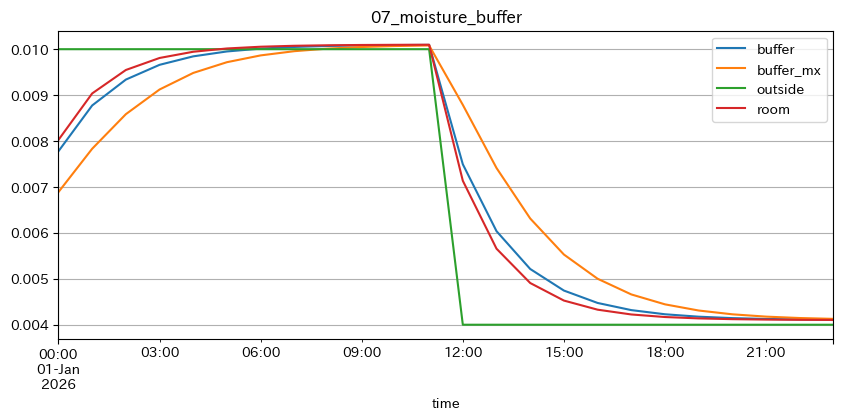

In [5]:
frames = {name: result.get_series_df('humidity_x', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_humidity_x.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
外気湿度が低下した後の応答遅れと水分収支を比べる。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S440 モリエル線図 R-32.ipynb
- S442 p-h Diagram for R-32.ipynb
- S443 モリエル線図 R-32.ipynb
- S444 湿り空気線図.ipynb
- S445 湿り空気線図_r2.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。